In [33]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

df = pd.read_csv("../data/raw/fraud_oracle.csv")

X = df.drop(
    columns=["FraudFound_P", "PolicyNumber", "RepNumber"]
)

y = df["FraudFound_P"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (12336, 30)
Testing: (3084, 30)


In [34]:
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

y_pred = baseline.predict(X_train)

print("Baseline classification results:")
print(classification_report(y_train, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_train, y_pred))

Baseline classification results:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97     11598
           1       0.00      0.00      0.00       738

    accuracy                           0.94     12336
   macro avg       0.47      0.50      0.48     12336
weighted avg       0.88      0.94      0.91     12336

Confusion matrix:
[[11598     0]
 [  738     0]]


In [36]:
baseline_accuracy = accuracy_score(y_train, y_pred)
baseline_precision = precision_score(y_train, y_pred, zero_division=0)
baseline_recall = recall_score(y_train, y_pred, zero_division=0)
baseline_f1 = f1_score(y_train, y_pred, zero_division=0)

baseline_pr_auc = average_precision_score(
    y_train,
    baseline.predict_proba(X_train)[:, 1]
)

print(f"Accuracy: {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall: {baseline_recall:.4f}")
print(f"F1-score: {baseline_f1:.4f}")
print(f"Average Precision: {baseline_pr_auc:.4f}")

Accuracy: 0.9402
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000
Average Precision: 0.0598


In [37]:
print("Current features:")
print(X_train.columns.tolist())

print("\nUnique values for selected features:")

for col in ["Year", "PoliceReportFiled", "WitnessPresent", "AgentType"]:
    print(f"\n{col}:")
    print(X_train[col].value_counts())

Current features:
['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'Deductible', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'Year', 'BasePolicy']

Unique values for selected features:

Year:
Year
1994    4949
1995    4152
1996    3235
Name: count, dtype: int64

PoliceReportFiled:
PoliceReportFiled
No     12004
Yes      332
Name: count, dtype: int64

WitnessPresent:
WitnessPresent
No     12266
Yes       70
Name: count, dtype: int64

AgentType:
AgentType
External    12132
Internal      204
Name: count, dtype: int64


In [38]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier

X_train = X_train.copy()
X_test = X_test.copy()

# Remembers which ages were missing before filling them.
X_train["AgeMissing"] = X_train["Age"].eq(0).astype(str)
X_test["AgeMissing"] = X_test["Age"].eq(0).astype(str)

# Zero is treated as an unknown age.
X_train["Age"] = X_train["Age"].replace(0, np.nan)
X_test["Age"] = X_test["Age"].replace(0, np.nan)

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

categorical_features += ["Year", "DriverRating"]

numerical_features = [
    col for col in X_train.select_dtypes(include="number").columns
    if col not in categorical_features
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Model preprocessing pipeline ready")

Model preprocessing pipeline ready


### Preparing the model inputs

Zero ages are treated as missing. AgeMissing records which ages
were unknown, while the median provides a numeric placeholder.

Numeric features are standardised for logistic regression.
Decision trees and Random Forest do not need scaling, but using
it here shares this preprocessing pipeline.

Categorical features are one-hot encoded so the models can use
them without assuming an order between categories.

The preprocessing stays inside each model pipeline, so the
imputer, scaler and encoder are fitted only on the training
part of each cross-validation fold.

Gaussian Naive Bayes uses a dense version of these inputs.
One-hot features do not follow a Gaussian distribution, which
is a limitation we need to consider when interpreting its results.

In [39]:
# Start with a small tree to limit how complex it can become.
# Depth 5 is a baseline choice, not a tuned best value.
decision_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        # Give fraud cases more weight because they are less common.
        class_weight="balanced",
        # Keep the experiment repeatable.
        random_state=42
    ))
])

# The pipeline learns preprocessing from the training data.
decision_tree.fit(X_train, y_train)

y_train_pred = decision_tree.predict(X_train)

# These results show how well the tree fits its training records.
# Cross-validation below checks performance on unseen records.
print("Decision Tree — Training Results")
print(classification_report(
    y_train,
    y_train_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, y_train_pred))

Decision Tree — Training Results
              precision    recall  f1-score   support

           0       1.00      0.61      0.76     11598
           1       0.13      0.95      0.23       738

    accuracy                           0.63     12336
   macro avg       0.56      0.78      0.50     12336
weighted avg       0.94      0.63      0.72     12336


Confusion Matrix:
[[7056 4542]
 [  35  703]]


In [40]:
# Checks the model on separate validation folds, rather than training records.
# Stratified folds keep a similar proportion of fraud cases in each fold.
# The pipeline fits preprocessing separately inside each training fold.

# Precision tells us how many fraud alerts were correct.
# Recall tells us how much of the actual fraud we detected.
# F1 balances precision and recall.
# Average precision measures how well the model ranks fraud cases.

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    decision_tree,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "average_precision": "average_precision"
    }
)

# Shows the average score and how much it varies between folds.
# The +/- value is the standard deviation, not a confidence interval.

for metric in [
    "precision",
    "recall",
    "f1",
    "average_precision"
]:
    values = scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} (+/- {values.std():.4f})")

precision: 0.1318 (+/- 0.0040)
recall: 0.9309 (+/- 0.0153)
f1: 0.2309 (+/- 0.0063)
average_precision: 0.1904 (+/- 0.0170)


In [41]:
# Logistic regression gives us a simple comparison with the tree models.
# We scale numeric inputs because their sizes can affect this model.
# Balanced class weights give the less common fraud cases more influence.

from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_train)

print("Logistic Regression — Training Results")
print(classification_report(
    y_train,
    logistic_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, logistic_pred))

Logistic Regression — Training Results
              precision    recall  f1-score   support

           0       0.99      0.64      0.78     11598
           1       0.14      0.90      0.24       738

    accuracy                           0.66     12336
   macro avg       0.56      0.77      0.51     12336
weighted avg       0.94      0.66      0.75     12336


Confusion Matrix:
[[7429 4169]
 [  71  667]]


In [42]:
# Use the same folds and metrics as the Decision Tree for a fair comparison.
# Preprocessing is fitted separately inside each training fold.

logistic_scores = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "average_precision": "average_precision"
    }
)

print("Logistic Regression — Cross-Validation")

for metric in ["precision", "recall", "f1", "average_precision"]:
    values = logistic_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} (+/- {values.std():.4f})")

Logistic Regression — Cross-Validation
precision: 0.1326 (+/- 0.0052)
recall: 0.8468 (+/- 0.0194)
f1: 0.2293 (+/- 0.0084)
average_precision: 0.1509 (+/- 0.0108)


In [43]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

# Gaussian Naive Bayes needs a dense input array.
nb_preprocessor = clone(preprocessor)
nb_preprocessor.set_params(cat__encoder__sparse_output=False)

nb_pipeline = Pipeline([
    ("preprocessor", nb_preprocessor),
    ("classifier", GaussianNB())
])

# Try different smoothing values to reduce unstable predictions
# caused by features with very small variances.
nb_search = GridSearchCV(
    estimator=nb_pipeline,
    param_grid={
        "classifier__var_smoothing": [
            1e-9, 1e-6, 1e-3, 0.1, 1.0
        ]
    },
    scoring="average_precision",
    cv=cv,
    n_jobs=-1
)

# Search using training data only. Keep the test set separate.
nb_search.fit(X_train, y_train)

naive_bayes_model = nb_search.best_estimator_

print("Best smoothing value:")
print(nb_search.best_params_)

print("\nBest development average precision:")
print(round(nb_search.best_score_, 4))

# These are training results, not an independent evaluation.
nb_pred = naive_bayes_model.predict(X_train)

print("\nNaive Bayes — Training Results")
print(classification_report(
    y_train,
    nb_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, nb_pred))

Best smoothing value:
{'classifier__var_smoothing': 0.1}

Best development average precision:
0.1561

Naive Bayes — Training Results
              precision    recall  f1-score   support

           0       0.96      0.86      0.91     11598
           1       0.17      0.46      0.25       738

    accuracy                           0.84     12336
   macro avg       0.57      0.66      0.58     12336
weighted avg       0.91      0.84      0.87     12336


Confusion Matrix:
[[9966 1632]
 [ 399  339]]


In [44]:
# These are development scores because the same folds were used
# to choose the smoothing value. They are not independent test results.

nb_scores = cross_validate(
    naive_bayes_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "average_precision": "average_precision"
    }
)

print("Naive Bayes — Cross-Validation")

for metric in ["precision", "recall", "f1", "average_precision"]:
    values = nb_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} (+/- {values.std():.4f})")

Naive Bayes — Cross-Validation
precision: 0.1581 (+/- 0.0204)
recall: 0.4213 (+/- 0.0360)
f1: 0.2296 (+/- 0.0258)
average_precision: 0.1561 (+/- 0.0106)


In [45]:
# Starts with 200 trees as a practical baseline.
# Depth 10 and at least 2 records per leaf limit tree complexity.
# These are starting settings, not the best settings from tuning.
# Balanced weights give fraud cases more influence during training.
# The search below tests alternative settings using cross-validation.

from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest.fit(X_train, y_train)

rf_train_pred = random_forest.predict(X_train)

print("Random Forest — Training Results")
print(classification_report(
    y_train,
    rf_train_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, rf_train_pred))

Random Forest — Training Results
              precision    recall  f1-score   support

           0       1.00      0.64      0.78     11598
           1       0.15      0.97      0.26       738

    accuracy                           0.66     12336
   macro avg       0.57      0.81      0.52     12336
weighted avg       0.95      0.66      0.75     12336


Confusion Matrix:
[[7478 4120]
 [  24  714]]


In [46]:
# Evaluates the forest using the same folds as the other baseline models.
# Uses these validation scores rather than training scores for comparison.

rf_scores = cross_validate(
    random_forest,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "average_precision": "average_precision"
    },
    n_jobs=-1
)

print("Random Forest — Cross-Validation")

for metric in ["precision", "recall", "f1", "average_precision"]:
    values = rf_scores[f"test_{metric}"]
    print(
        f"{metric}: {values.mean():.4f} "
        f"(+/- {values.std():.4f})"
    )

Random Forest — Cross-Validation
precision: 0.1383 (+/- 0.0009)
recall: 0.8876 (+/- 0.0211)
f1: 0.2392 (+/- 0.0010)
average_precision: 0.2244 (+/- 0.0228)


In [47]:
# Try 12 combinations of forest settings to keep runtime manageable.
# Compare them using average precision because fraud cases are uncommon.
# All tuning uses training data; the test set stays separate.

from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

rf_search = RandomizedSearchCV(
    estimator=random_forest,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation average precision:")
print(round(rf_search.best_score_, 4))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': None, 'classifier__class_weight': 'balanced_subsample'}

Best cross-validation average precision:
0.2417


In [48]:
best_rf = rf_search.best_estimator_

print("Best Random Forest configuration:")
print(best_rf.named_steps["classifier"])

print("\nTraining classification results:")
best_rf_train_pred = best_rf.predict(X_train)

print(classification_report(
    y_train,
    best_rf_train_pred,
    zero_division=0
))

Best Random Forest configuration:
RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=2,
                       min_samples_split=10, n_estimators=200, n_jobs=-1,
                       random_state=42)

Training classification results:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     11598
           1       0.94      0.99      0.96       738

    accuracy                           1.00     12336
   macro avg       0.97      0.99      0.98     12336
weighted avg       1.00      1.00      1.00     12336



In [49]:
from sklearn.base import clone

tuned_rf_scores = cross_validate(
    clone(best_rf),
    X_train,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "average_precision": "average_precision"
    },
    n_jobs=-1
)

print("Tuned Random Forest — Cross-Validation")

for metric in ["precision", "recall", "f1", "average_precision"]:
    values = tuned_rf_scores[f"test_{metric}"]
    print(
        f"{metric}: {values.mean():.4f} "
        f"(+/- {values.std():.4f})"
    )

Tuned Random Forest — Cross-Validation
precision: 0.4236 (+/- 0.0997)
recall: 0.1003 (+/- 0.0130)
f1: 0.1616 (+/- 0.0228)
average_precision: 0.2417 (+/- 0.0384)


In [50]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

rf_oof_proba = cross_val_predict(
    clone(best_rf),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold probabilities generated successfully")

Out-of-fold probabilities generated successfully


In [51]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

threshold_results = []

for threshold in thresholds:
    predictions = (rf_oof_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1
0,0.1,0.1232,0.9593,0.2184
1,0.2,0.1470,0.8455,0.2505
2,0.3,0.1957,0.5041,0.2819
3,0.4,0.2834,0.2331,0.2558
4,0.5,0.4134,0.1003,0.1614


In [52]:
potential_leakage_features = [
    "Fault",
    "PoliceReportFiled",
    "WitnessPresent"
]

print("Potential leakage features:")
for col in potential_leakage_features:
    print(col, "-", col in X_train.columns)

X_train_safe = X_train.drop(
    columns=potential_leakage_features,
    errors="ignore"
).copy()

X_test_safe = X_test.drop(
    columns=potential_leakage_features,
    errors="ignore"
).copy()

print("\nTraining shape:", X_train_safe.shape)
print("Testing shape:", X_test_safe.shape)

Potential leakage features:
Fault - True
PoliceReportFiled - True
WitnessPresent - True

Training shape: (12336, 28)
Testing shape: (3084, 28)


In [63]:
from sklearn.base import clone

categorical_safe = X_train_safe.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

categorical_safe += ["Year", "DriverRating"]

numeric_safe = [
    col for col in X_train_safe.select_dtypes(include="number").columns
    if col not in categorical_safe
]

safe_preprocessor = ColumnTransformer([
    ("num", clone(numeric_transformer), numeric_safe),
    ("cat", clone(categorical_transformer), categorical_safe)
])

print("Safe preprocessing pipeline created")
print("Categorical features:", len(categorical_safe))
print("Numerical features:", len(numeric_safe))

Safe preprocessing pipeline created
Categorical features: 24
Numerical features: 4


In [64]:
from sklearn.model_selection import RandomizedSearchCV, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# These inputs exclude the three potentially timing-sensitive features.
# Tune this version separately because its inputs have changed.
safe_rf_pipeline = Pipeline([
    ("preprocessor", safe_preprocessor),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# Reuse the parameter ranges from the earlier forest search.
# Try 8 combinations to keep the search manageable.
safe_search = RandomizedSearchCV(
    estimator=safe_rf_pipeline,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

# Only training records are used to choose the settings.
safe_search.fit(X_train_safe, y_train)

# Use the tuned model in the remaining cells.
safe_rf = safe_search.best_estimator_

print("Best reduced-feature Random Forest settings:")
print(safe_search.best_params_)

safe_scores = cross_validate(
    safe_rf,
    X_train_safe,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "average_precision": "average_precision"
    },
    n_jobs=-1
)

# These are development scores because these folds also guided tuning.
print("\nTuned reduced-feature Random Forest — Development Results")

for metric in ["precision", "recall", "f1", "average_precision"]:
    values = safe_scores[f"test_{metric}"]
    print(
        f"{metric}: {values.mean():.4f} "
        f"(+/- {values.std():.4f})"
    )

Best reduced-feature Random Forest settings:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_depth': 15, 'classifier__class_weight': 'balanced'}

Tuned reduced-feature Random Forest — Development Results
precision: 0.1455 (+/- 0.0112)
recall: 0.4281 (+/- 0.0228)
f1: 0.2171 (+/- 0.0153)
average_precision: 0.1695 (+/- 0.0163)


In [65]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

safe_oof_proba = cross_val_predict(
    clone(safe_rf),
    X_train_safe,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    predictions = (safe_oof_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        )
    })

safe_threshold_df = pd.DataFrame(threshold_results)

display(safe_threshold_df.round(4))

print(
    "Out-of-fold average precision:",
    round(average_precision_score(y_train, safe_oof_proba), 4)
)

,Threshold,Precision,Recall,F1
0,0.1,0.0788,0.9661,0.1458
1,0.2,0.0845,0.9580,0.1554
2,0.3,0.0886,0.9350,0.1618
3,0.4,0.1023,0.7696,0.1805
4,0.5,0.1452,0.4282,0.2169
5,0.6,0.2338,0.1707,0.1973
6,0.7,0.3173,0.0447,0.0784


Out-of-fold average precision: 0.1623


In [66]:
final_rf = clone(safe_rf)

final_rf.fit(X_train_safe, y_train)

test_probabilities = final_rf.predict_proba(X_test_safe)[:, 1]

# Choose the threshold with the highest F1 on training validation predictions.
# Test results are not used to make this choice.
best_threshold_index = safe_threshold_df["F1"].idxmax()
final_threshold = float(
    safe_threshold_df.loc[best_threshold_index, "Threshold"]
)

print("Selected threshold:", round(final_threshold, 2))

test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

print("Final Random Forest — Test Results")
print(classification_report(
    y_test,
    test_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nAverage Precision:")
print(round(
    average_precision_score(y_test, test_probabilities),
    4
))

Selected threshold: 0.5
Final Random Forest — Test Results
              precision    recall  f1-score   support

           0       0.96      0.83      0.89      2899
           1       0.15      0.46      0.22       185

    accuracy                           0.80      3084
   macro avg       0.55      0.65      0.56      3084
weighted avg       0.91      0.80      0.85      3084


Confusion Matrix:
[[2396  503]
 [  99   86]]

Average Precision:
0.1663


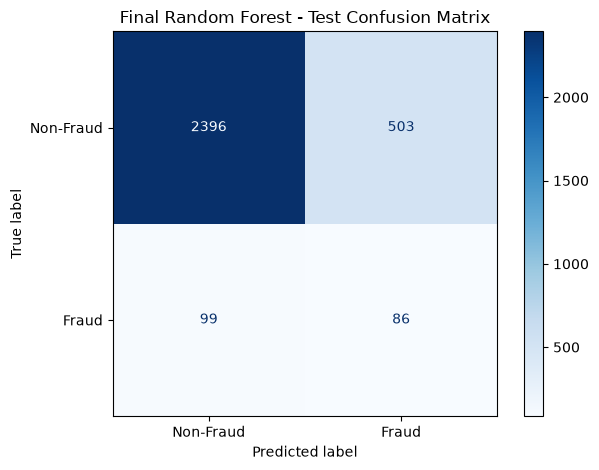

In [67]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Non-Fraud", "Fraud"],
    cmap="Blues",
    values_format="d"
)

plt.title("Final Random Forest - Test Confusion Matrix")
plt.tight_layout()
plt.show()


Development cross-validation results


,Model,CV F1,CV Average Precision
0,Decision Tree,0.2309,0.1904
1,Logistic Regression,0.2293,0.1509
2,Tuned Gaussian Naive Bayes,0.2296,0.1561
3,Original Random Forest,0.2392,0.2244
4,Tuned Random Forest,0.1616,0.2417
5,Tuned Reduced-Feature Random Forest,0.2171,0.1695
6,Original MLP,0.1911,0.1724
7,Regularized MLP,0.1967,0.1752


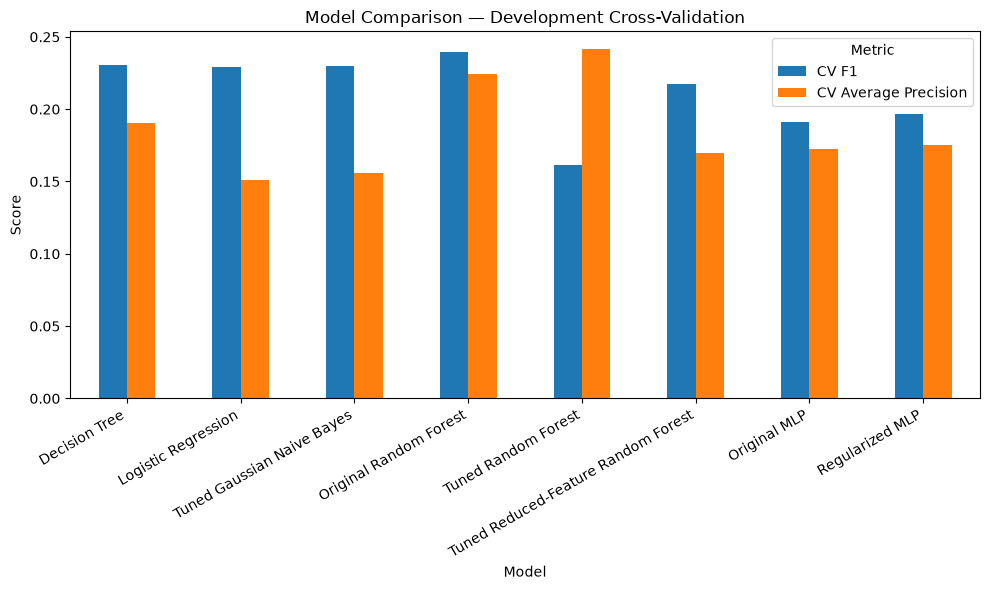

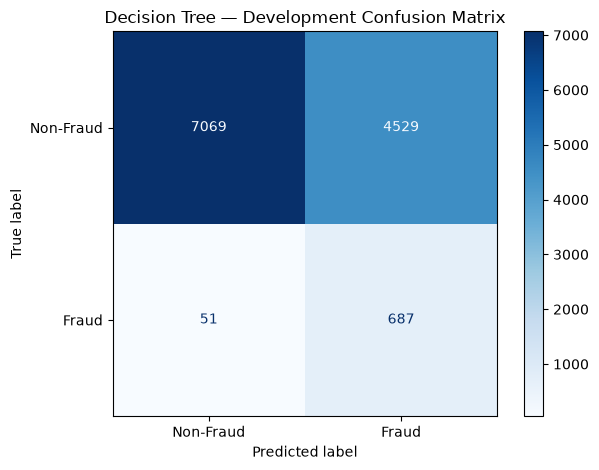

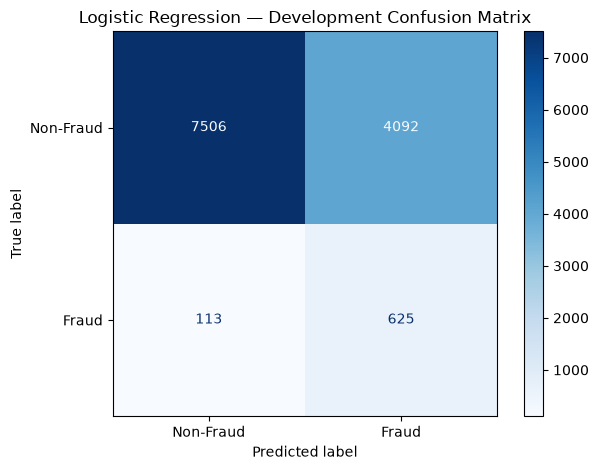

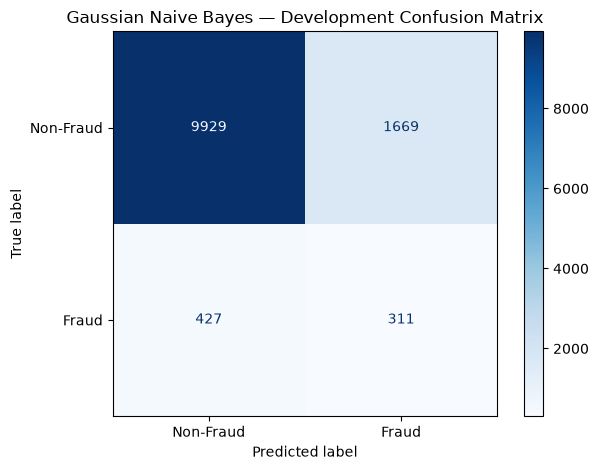

In [74]:

# Read the scores from the experiments instead of typing fixed numbers.
model_scores = {
    "Decision Tree": scores,
    "Logistic Regression": logistic_scores,
    "Tuned Gaussian Naive Bayes": nb_scores,
    "Original Random Forest": rf_scores,
    "Tuned Random Forest": tuned_rf_scores,
    "Tuned Reduced-Feature Random Forest": safe_scores
}

comparison_rows = []

for name, results in model_scores.items():
    comparison_rows.append({
        "Model": name,
        "CV F1": results["test_f1"].mean(),
        "CV Average Precision": results["test_average_precision"].mean()
    })

model_comparison = pd.DataFrame(comparison_rows)

from pathlib import Path

# Read the scores saved by the MLP notebook.
mlp_results = pd.read_csv(
    Path("../results/tabular/mlp_cv_comparison.csv")
)

# Match the column names used in this comparison.
mlp_results = mlp_results[
    ["Model", "F1", "Average Precision"]
].rename(columns={
    "F1": "CV F1",
    "Average Precision": "CV Average Precision"
})

# Include both MLP configurations without typing their scores manually.
model_comparison = pd.concat(
    [model_comparison, mlp_results],
    ignore_index=True
)

# Save the full development comparison for the report.
model_comparison.to_csv(
    Path("../results/tabular/model_cv_comparison.csv"),
    index=False
)

print("Development cross-validation results")
display(model_comparison.round(4))

# Show the same results as a chart for easier comparison.
model_comparison.set_index("Model").plot.bar(
    figsize=(10, 6)
)

plt.title("Model Comparison — Development Cross-Validation")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict

# Use validation predictions so each record is predicted
# by a model that was not trained on that record.
baseline_models = {
    "Decision Tree": decision_tree,
    "Logistic Regression": logistic_model,
    "Gaussian Naive Bayes": naive_bayes_model
}

for name, model in baseline_models.items():
    predictions = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict",
        n_jobs=-1
    )

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        predictions,
        display_labels=["Non-Fraud", "Fraud"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(name + " — Development Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [69]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

final_results = pd.DataFrame([{
    "Model": "Reduced-Feature Random Forest",
    "Threshold": final_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Fraud Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Fraud Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "Fraud F1": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "Average Precision": average_precision_score(
        y_test, test_probabilities
    )
}])

print("Final Held-Out Test Results")
display(final_results.round(4))


Final Held-Out Test Results


,Model,Threshold,Accuracy,Fraud Precision,Fraud Recall,Fraud F1,Average Precision
0,Reduced-Feature Random Forest,0.5,0.8048,0.146,0.4649,0.2222,0.1663


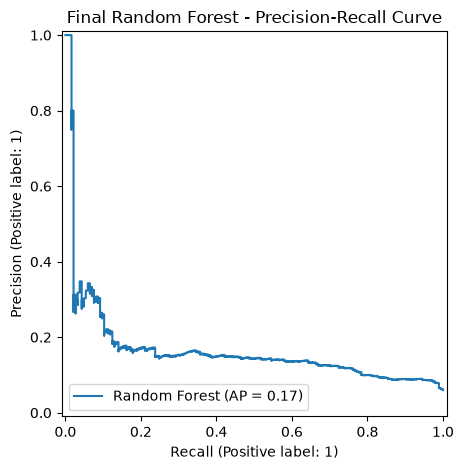

In [70]:

import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities,
    name="Random Forest"
)

plt.title("Final Random Forest - Precision-Recall Curve")
plt.tight_layout()
plt.show()


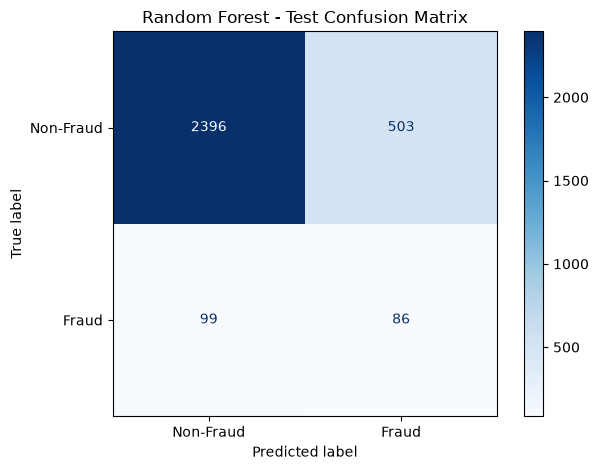

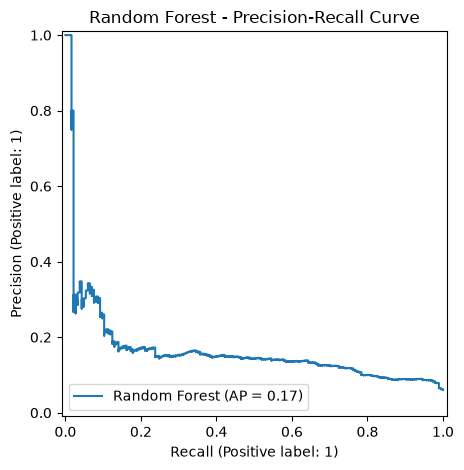

Evaluation figures saved successfully


In [71]:

from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay

results_dir = Path("../results/tabular")
results_dir.mkdir(parents=True, exist_ok=True)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Non-Fraud", "Fraud"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    results_dir / "rf_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities,
    name="Random Forest"
)

plt.title("Random Forest - Precision-Recall Curve")
plt.tight_layout()
plt.savefig(
    results_dir / "rf_precision_recall.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Evaluation figures saved successfully")
